In [1]:
%load_ext autoreload
%autoreload 2

import os
import pickle
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

os.environ["NM_PIPELINE"] = "p3"
sys.path.insert(0, str(Path.cwd().parents[1]))
from viz_style import apply_style, FS_ANNOT_LG, FS_ANNOT_SM
apply_style()

import MixedEffectsModeling.config as config
from MixedEffectsModeling.core.model_engine_mixed import NormativeModelEngineMixed
from MixedEffectsModeling.core.ood_filter import MahalanobisFilter, RangeFilter
from MixedEffectsModeling.core.shash import load_shash_params, shash_correct_matrix
from MixedEffectsModeling.validation.lobo_engine import load_full_data

ZDIR = config.ZSCORES_MIXED_DIR
FIGDIR = config.DISEASE_SCORING_FIG_DIR
FIGDIR.mkdir(parents=True, exist_ok=True)
ZDIR.mkdir(parents=True, exist_ok=True)

%matplotlib inline

In [2]:
# 0. Load production engine + disease covariates/counts (non-HC rows of the same QC-filtered cohort LOBO uses)
engine = NormativeModelEngineMixed.load(config.ENGINE_MIXED_DIR)
gene_names = [g for g in engine.genes if engine.genes[g].ok]

data = load_full_data()
dis_idx = np.where(~data['is_hc'])[0]
X_all = engine.covariates.transform(data['obs'], data['Y'])
X_dis = X_all[dis_idx]
Y_dis = data['Y'][dis_idx][:, [data['gene_col'][g] for g in gene_names]]
names_dis = data['names'][dis_idx]
batch_dis = data['batch'][dis_idx]
phenotype_dis = data['phenotype'][dis_idx]

print(f"engine genes (ok): {len(gene_names)}")
print(f"disease samples: {len(dis_idx)}")
print(pd.Series(phenotype_dis).value_counts())

engine genes (ok): 19914
disease samples: 747
Tuberculosis          103
ME/CFS                 90
Pancreatitis           81
Pancreatic Cancer      74
Pre-eclampsia          62
Liver Cancer           48
Colorectal Cancer      41
Lung Cancer            33
Stomach Cancer         29
CAD_HF+                29
CAD_HF-                29
Esophagus Cancer       27
MM                     18
Other Cancer           18
HIV                    13
HIV + Tuberculosis     11
ICI-m                  11
ICI-treated Cancer     11
MGUS                    8
Pancreatic Cancer       6
Liver Cirrhosis         5
Name: count, dtype: int64


In [3]:
hc_train_mask = data['is_hc'] & ~np.isin(data['batch'], list(data['small_hc_batches']))
X_hc = X_all[hc_train_mask]

B_hc, B_dis = data['X_raw'][hc_train_mask], data['X_raw'][dis_idx]
ood = MahalanobisFilter(percentile=95).fit(B_hc)
mahal_dist = ood.distances(B_dis)
mahal_keep = mahal_dist <= ood.threshold_
rng_filter = RangeFilter(n_out_thr=2).fit(B_hc)
n_out = rng_filter.n_out(B_dis)
range_keep = rng_filter.mask(B_dis)

ood_keep = mahal_keep & range_keep

summary = (pd.DataFrame({'phenotype': phenotype_dis, 'keep': ood_keep})
          .groupby('phenotype')['keep']
          .agg(n_total='size', n_kept='sum')
          .assign(pct_removed=lambda d: (1 - d['n_kept'] / d['n_total']) * 100)
          .sort_values('pct_removed', ascending=False))
print(f"Mahalanobis P95 threshold: {ood.threshold_:.2f}  (flagged {int((~mahal_keep).sum())})")
print(f"Range filter (>={rng_filter.n_out_thr} axes outside HC p1-p99): flagged {int((~range_keep).sum())}")
print(f"combined: kept {ood_keep.sum()}/{len(ood_keep)} ({(~ood_keep).mean()*100:.1f}% flagged OOD)")
print(summary.to_string())

Mahalanobis P95 threshold: 5.21  (flagged 40)
Range filter (>=2 axes outside HC p1-p99): flagged 31
combined: kept 694/747 (7.1% flagged OOD)
                    n_total  n_kept  pct_removed
phenotype                                       
Pancreatic Cancer         6       2    66.666667
Stomach Cancer           29      22    24.137931
Liver Cirrhosis           5       4    20.000000
Lung Cancer              33      27    18.181818
Liver Cancer             48      40    16.666667
Colorectal Cancer        41      35    14.634146
Other Cancer             18      16    11.111111
CAD_HF-                  29      26    10.344828
CAD_HF+                  29      26    10.344828
ICI-m                    11      10     9.090909
HIV + Tuberculosis       11      10     9.090909
ICI-treated Cancer       11      10     9.090909
HIV                      13      12     7.692308
Esophagus Cancer         27      25     7.407407
Pancreatic Cancer        74      72     2.702703
Pancreatitis             

21 phenotypes, 747 disease samples scored
                    n_total  n_kept
phenotype                          
Pancreatic Cancer         6       2
Stomach Cancer           29      22
Liver Cirrhosis           5       4
Lung Cancer              33      27
Liver Cancer             48      40
Colorectal Cancer        41      35
Other Cancer             18      16
CAD_HF-                  29      26
CAD_HF+                  29      26
ICI-m                    11      10
HIV + Tuberculosis       11      10
ICI-treated Cancer       11      10
HIV                      13      12
Esophagus Cancer         27      25
Pancreatic Cancer        74      72
Pancreatitis             81      79
Tuberculosis            103     101
Pre-eclampsia            62      61
ME/CFS                   90      90
MGUS                      8       8
MM                       18      18


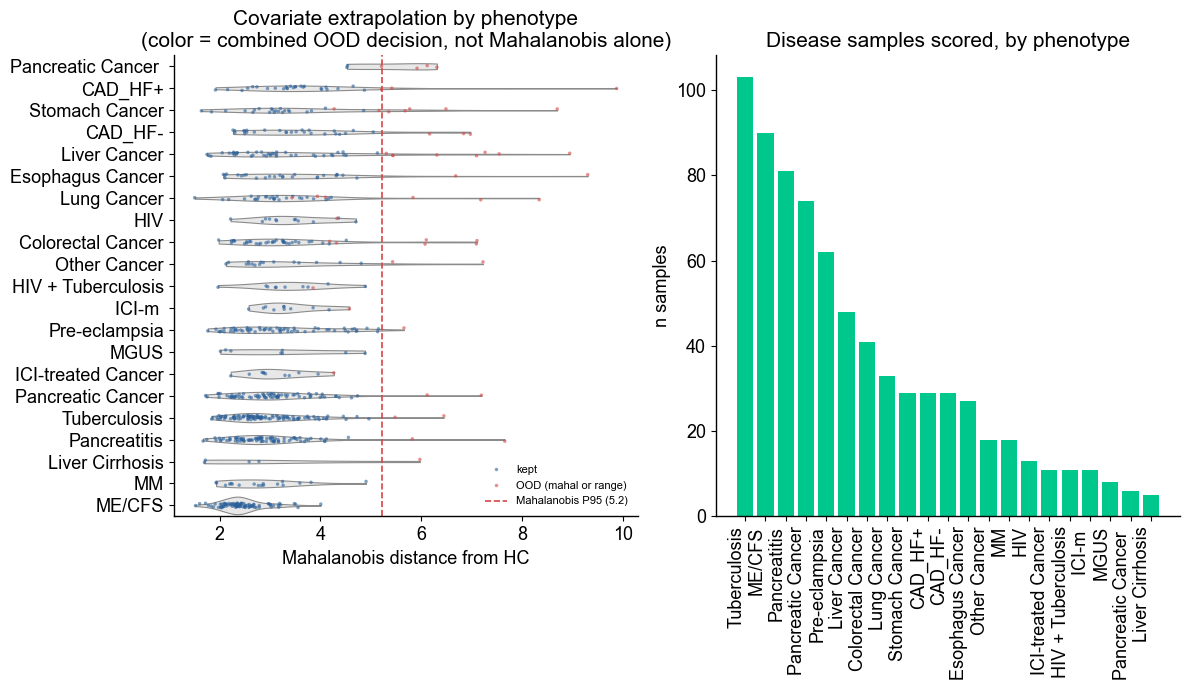

In [4]:
print(f"{summary.shape[0]} phenotypes, {len(phenotype_dis)} disease samples scored")
print(summary[['n_total', 'n_kept']].to_string())

vio = pd.DataFrame({'phenotype': phenotype_dis, 'mahal_dist': mahal_dist, 'n_out': n_out,
                    'flag': np.where(ood_keep, 'kept', 'OOD (mahal or range)')})
order_mahal = vio.groupby('phenotype')['mahal_dist'].mean().sort_values(ascending=False).index
order_count = summary.sort_values('n_total', ascending=False).index

fig, axes = plt.subplots(1, 2, figsize=(12, 7))

# violin shows the Mahalanobis axis, but point color is the COMBINED decision (mahal OR range) --
# a point can sit left of the Mahalanobis line and still be red if the range filter caught it
sns.violinplot(data=vio, y='phenotype', x='mahal_dist', order=order_mahal,
               color='#e8e8e8', orient='h', cut=0, inner=None, linewidth=0.8, ax=axes[0])
sns.stripplot(data=vio, y='phenotype', x='mahal_dist', order=order_mahal, hue='flag',
              hue_order=['kept', 'OOD (mahal or range)'], palette=['#2a6099', '#d64545'],
              orient='h', size=2.5, alpha=0.6, jitter=True, ax=axes[0])
axes[0].axvline(ood.threshold_, color='#d64545', ls='--', lw=1.2, label=f'Mahalanobis P95 ({ood.threshold_:.1f})')
axes[0].set_xlabel('Mahalanobis distance from HC')
axes[0].set_ylabel('')
axes[0].set_title('Covariate extrapolation by phenotype\n(color = combined OOD decision, not Mahalanobis alone)')
handles, labels = axes[0].get_legend_handles_labels()
axes[0].legend(handles, labels, frameon=False, fontsize=FS_ANNOT_SM, loc='lower right')

axes[1].bar(range(len(order_count)), summary.loc[order_count, 'n_total'], color='#00C78B')
axes[1].set_xticks(range(len(order_count)))
axes[1].set_xticklabels(order_count, rotation=90, ha='right')
axes[1].set_ylabel('n samples')
axes[1].set_title('Disease samples scored, by phenotype')

plt.tight_layout()
fig.savefig(FIGDIR / 'phenotype_summary.png', bbox_inches='tight')

In [5]:
# 1. Score (raw RQR) -- cache-first
Z_CAP = 10.0  # |Z| beyond this is already p~1e-23 -- clip only tames the axis, doesn't change BH calls
Z_PATH = ZDIR / 'Z_disease.npy'
GENES_PATH = ZDIR / 'gene_names.pkl'
META_PATH = ZDIR / 'sample_meta.csv'

if Z_PATH.exists():
    Z = np.load(Z_PATH)
else:
    Z = np.clip(engine.score(X_dis, Y_dis, gene_names=gene_names), -Z_CAP, Z_CAP)
    np.save(Z_PATH, Z)
    with open(GENES_PATH, 'wb') as f:
        pickle.dump(gene_names, f)

pd.DataFrame({'sample': names_dis, 'batch': batch_dis, 'phenotype': phenotype_dis,
             'ood_keep': ood_keep, 'mahal_dist': mahal_dist, 'n_out': n_out}).to_csv(META_PATH, index=False)

print(f"Z shape: {Z.shape}, finite frac: {np.isfinite(Z).mean():.4f}, max |Z|: {np.nanmax(np.abs(Z)):.2f}")

Z shape: (747, 19914), finite frac: 1.0000, max |Z|: 7.94


In [6]:
# 2. SHASH-correct -- cache-first
Z_SHASH_PATH = ZDIR / 'Z_disease_shash.npy'

# loaded outside the cache branch: cell 2b needs it even when this matrix comes from disk
shash_params = load_shash_params(config.ENGINE_MIXED_DIR / 'training_summary.csv')  # engine's own in-sample SHASH fit, see model_engine_mixed.NormativeModelEngineMixed.fit_shash

if Z_SHASH_PATH.exists():
    Z_shash = np.load(Z_SHASH_PATH)
else:
    Z_shash = shash_correct_matrix(np.nan_to_num(Z, nan=0.0, posinf=10.0, neginf=-10.0), gene_names, shash_params)
    Z_shash = np.clip(Z_shash, -Z_CAP, Z_CAP)
    Z_shash[~np.isfinite(Z)] = np.nan
    np.save(Z_SHASH_PATH, Z_shash)

print(f"Z_shash shape: {Z_shash.shape}")
print(f"mean |Z| raw vs shash: {np.nanmean(np.abs(Z)):.4f} vs {np.nanmean(np.abs(Z_shash)):.4f}")
print(f"max |Z_shash|: {np.nanmax(np.abs(Z_shash)):.2f}")

Z_shash shape: (747, 19914)
mean |Z| raw vs shash: 0.8675 vs 0.8766
max |Z_shash|: 10.00


In [7]:
# 2b. In-sample HC Z (production null, used by fit_shash internally but never persisted) -- cache-first
HC_Z_PATH = ZDIR / 'Z_hc.npy'
HC_Z_SHASH_PATH = ZDIR / 'Z_hc_shash.npy'
HC_META_PATH = ZDIR / 'hc_meta.csv'

names_hc = data['names'][hc_train_mask]
batch_hc_names = data['batch'][hc_train_mask]
Y_hc = data['Y'][hc_train_mask][:, [data['gene_col'][g] for g in gene_names]]

if HC_Z_SHASH_PATH.exists():
    Z_hc_shash = np.load(HC_Z_SHASH_PATH)
else:
    Z_hc = np.clip(engine.score(X_hc, Y_hc, gene_names=gene_names), -Z_CAP, Z_CAP)
    np.save(HC_Z_PATH, Z_hc)
    Z_hc_shash = shash_correct_matrix(np.nan_to_num(Z_hc, nan=0.0, posinf=10.0, neginf=-10.0), gene_names, shash_params)
    Z_hc_shash = np.clip(Z_hc_shash, -Z_CAP, Z_CAP)
    Z_hc_shash[~np.isfinite(Z_hc)] = np.nan
    np.save(HC_Z_SHASH_PATH, Z_hc_shash)
    pd.DataFrame({'sample': names_hc, 'batch': batch_hc_names}).to_csv(HC_META_PATH, index=False)

print(f"Z_hc_shash shape: {Z_hc_shash.shape}, finite frac: {np.isfinite(Z_hc_shash).mean():.4f}")
print(f"HC marginal: mean={np.nanmean(Z_hc_shash):.4f} std={np.nanstd(Z_hc_shash):.4f}")

Z_hc_shash shape: (592, 19914), finite frac: 1.0000
HC marginal: mean=0.0000 std=0.9998


In [8]:
from scipy.stats import norm

from MixedEffectsModeling.core.calibration import bh_fdr_reject
FDR_Q = 0.05

# per-sample BH-significant gene count + critical p-value, cache-first
SIG_PATH = ZDIR / 'sample_bh_sig.csv'
if SIG_PATH.exists():
    sig_df = pd.read_csv(SIG_PATH)
else:
    p_all = 2 * norm.sf(np.abs(Z_shash))
    n_sig = np.zeros(len(names_dis), dtype=int)
    p_thr = np.full(len(names_dis), np.nan)
    for i in range(len(names_dis)):
        row = p_all[i]
        row = row[np.isfinite(row)]
        if len(row) == 0:
            continue
        reject = bh_fdr_reject(row, q=FDR_Q)
        n_sig[i] = int(reject.sum())
        if reject.any():
            p_thr[i] = float(row[reject].max())
    sig_df = pd.DataFrame({'sample': names_dis, 'phenotype': phenotype_dis, 'ood_keep': ood_keep,
                           'n_sig': n_sig, 'p_thr': p_thr})
    sig_df.to_csv(SIG_PATH, index=False)

top = sig_df[sig_df['ood_keep']].sort_values('n_sig', ascending=False).head(20)
print(top[['sample', 'phenotype', 'n_sig', 'p_thr']].to_string(index=False))

     sample         phenotype  n_sig    p_thr
SRR14506722       Lung Cancer   2749 0.006875
SRR14506735      Liver Cancer   2479 0.006217
SRR15619070                MM   2400 0.006021
SRR14506707       Lung Cancer   2224 0.005563
SRR14506777    Stomach Cancer   2122 0.005322
SRR14506768    Stomach Cancer   1789 0.004489
SRR14506728      Liver Cancer   1701 0.004266
SRR14506706       Lung Cancer   1611 0.004042
SRR28475993               HIV   1478 0.003707
SRR14506720       Lung Cancer   1101 0.002764
SRR14506693       Lung Cancer   1038 0.002606
SRR14506816 Colorectal Cancer   1002 0.002514
SRX16239407           CAD_HF-    962 0.002409
SRR33475199            ICI-m     961 0.002398
SRR33475188            ICI-m     910 0.002278
SRR14506692       Lung Cancer    734 0.001842
SRR15618989                MM    707 0.001775
SRR33475193            ICI-m     676 0.001690
SRX16239487           CAD_HF-    630 0.001572
SRR33475189            ICI-m     546 0.001359


In [9]:
import scanpy as sc

CHROM_ORDER = [f'chr{i}' for i in range(1, 23)] + ['chrX', 'chrY', 'chrM']
chrom_rank = {c: i for i, c in enumerate(CHROM_ORDER)}

var = sc.read_h5ad(config.H5AD_PATH, backed='r').var.loc[gene_names, ['Chromosome']].copy()
var['rank'] = var['Chromosome'].map(chrom_rank).astype(float).fillna(len(CHROM_ORDER))
var = var.sort_values('rank', kind='stable')  # stable: keeps var's own (genomic-proxy) order within a chromosome
var['x'] = range(len(var))

gene_x = var['x'].to_dict()
x_pos = np.array([gene_x[g] for g in gene_names])
chrom_of = var['Chromosome']
tick_df = var.groupby('Chromosome')['x'].median().reindex([c for c in CHROM_ORDER if c in var['Chromosome'].values])
tick_x = tick_df.values
tick_lab = [c.replace('chr', '') for c in tick_df.index]

/tmp/ipykernel_401942/2890160353.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  tick_df = var.groupby('Chromosome')['x'].median().reindex([c for c in CHROM_ORDER if c in var['Chromosome'].values])


In [10]:
import json

REF_DIR = config.DISEASE_REF_DIR
MARKER_TOPN = 500
MARKER_SCORE_FLOOR = 0.01

sym_of = sc.read_h5ad(config.H5AD_PATH, backed='r').var['GeneName'].reindex(gene_names)
sym2cols = {}
for j, sym in enumerate(sym_of.values):
    sym2cols.setdefault(sym, []).append(j)

pheno_markers = {}
pheno_scores = {}  # sym -> OT association score, drives both label ranking and sample ranking below
for f in REF_DIR.glob('*.json'):
    rec = json.load(open(f))
    if rec['phenotype'] == 'MGUS':  # OT association pool too thin (22 genes) for any panel size
        continue
    ranked = sorted(rec['genes'], key=lambda gs: -gs[1])
    floored = [g for g, s in ranked if s >= MARKER_SCORE_FLOOR]
    genes = set(floored[:MARKER_TOPN]) | set(rec.get('supplement', {}).get('genes', []))
    pheno_markers[rec['phenotype']] = genes
    pheno_scores[rec['phenotype']] = dict(rec['genes'])

p_all = 2 * norm.sf(np.abs(Z_shash))
phenotype_stripped = pd.Series(phenotype_dis).str.strip().values
p_thr_of = sig_df.set_index('sample')['p_thr']
n_sig_of = sig_df.set_index('sample')['n_sig']  # genome-wide BH-significant gene count, not just markers

rows = []
for i, (name, ph) in enumerate(zip(names_dis, phenotype_stripped)):
    markers = pheno_markers.get(ph)
    scores = pheno_scores.get(ph, {})
    p_thr = p_thr_of.get(name, np.nan)
    marker_cols = sorted({j for sym in (markers or []) for j in sym2cols.get(sym, [])})
    hit_syms = ([] if not marker_cols or not np.isfinite(p_thr)
                else sorted({sym_of.iloc[j] for j in marker_cols if p_all[i, j] <= p_thr}))
    hit_scores = [scores.get(s, 0.0) for s in hit_syms]
    rows.append((name, ph, ood_keep[i], len(marker_cols), len(hit_syms), ';'.join(hit_syms), int(n_sig_of.get(name, 0)),
                float(np.sum(hit_scores)), float(np.mean(hit_scores)) if hit_scores else 0.0))

marker_df = pd.DataFrame(rows, columns=['sample', 'phenotype', 'ood_keep', 'n_markers_tested',
                                        'n_markers_sig', 'marker_genes_sig', 'n_sig_genome',
                                        'marker_score_sum', 'marker_score_mean'])
marker_df['frac_markers_sig'] = marker_df['n_markers_sig'] / marker_df['n_markers_tested'].replace(0, np.nan)
marker_df.to_csv(ZDIR / 'sample_marker_hits.csv', index=False)

print(marker_df.groupby('phenotype').agg(
    n_samples=('sample', 'size'), n_markers=('n_markers_tested', 'first'),
    mean_n_sig_genome=('n_sig_genome', 'mean'), mean_frac_sig=('frac_markers_sig', 'mean')).to_string())
marker_df[marker_df['ood_keep'] & (marker_df['n_markers_tested'] > 0)].sort_values(
    'marker_score_sum', ascending=False).head(15)

                    n_samples  n_markers  mean_n_sig_genome  mean_frac_sig
phenotype                                                                 
CAD_HF+                    29          0         122.862069            NaN
CAD_HF-                    29          0          85.896552            NaN
Colorectal Cancer          41        500         259.414634       0.019805
Esophagus Cancer           27        498         112.814815       0.005429
HIV                        13        499         197.615385       0.011870
HIV + Tuberculosis         11        488         123.363636       0.008942
ICI-m                      11          0         477.000000            NaN
ICI-treated Cancer         11          0           9.000000            NaN
Liver Cancer               48        500         744.750000       0.038958
Liver Cirrhosis             5        497         292.200000       0.013280
Lung Cancer                33        501         719.696970       0.042279
ME/CFS                   

,sample,phenotype,ood_keep,n_markers_tested,n_markers_sig,marker_genes_sig,n_sig_genome,marker_score_sum,marker_score_mean,frac_markers_sig
56,SRR14506722,Lung Cancer,True,501,82,ACKR3;AFDN;AKT1;ALK;AR;ARHGAP35;ARID1A;ARNT;AT...,2749,41.4044,0.504932,0.163673
43,SRR14506707,Lung Cancer,True,501,67,AKT1;AKT2;ARID1B;ARID2;ARNT;ATIC;ATP2B3;BCL10;...,2224,34.6786,0.517591,0.133733
126,SRR14506816,Colorectal Cancer,True,500,66,ABL1;AFDN;AFF4;AKT2;APC;ARID1A;ARID1B;ARID2;AT...,1002,33.2488,0.503770,0.132000
61,SRR14506728,Liver Cancer,True,500,77,ABI1;ASXL1;ATM;BCL10;BCL11B;BIRC3;BRD4;BTG1;CA...,1701,25.9864,0.337486,0.154000
29,SRR14506693,Lung Cancer,True,501,48,APC;ARID1B;ARID2;ATF1;ATM;ATRX;BCOR;BRCA1;CDKN...,1038,24.2516,0.505242,0.095808
93,SRR14506777,Stomach Cancer,True,501,53,ABL1;AFF4;ALK;APC;ATF1;ATM;BCL10;BRD3;CDKN2C;C...,2122,23.9254,0.451423,0.105788
86,SRR14506768,Stomach Cancer,True,501,55,AFDN;AKT2;AR;ARID1A;ATM;AXIN1;BAP1;BARD1;BCORL...,1789,23.7384,0.431607,0.109780
199,SRR15619070,MM,True,499,59,ABCB1;AMER1;ARNT;ATR;CD274;CD38;CD79A;CDCA7L;C...,2400,22.5820,0.382746,0.118236
42,SRR14506706,Lung Cancer,True,501,42,ARID2;ATR;CACNA1D;CARS1;CD3E;CHEK2;CIC;CXCR4;E...,1611,22.0241,0.524383,0.083832
67,SRR14506735,Liver Cancer,True,500,52,ALK;APC;ATF1;ATM;BLM;BRAF;CDH11;CDKN2A;CDKN2C;...,2479,19.9171,0.383021,0.104000


In [11]:
# 3. Curation for the Manhattan panels -- two independent axes, top-N each, pancreatic only,
#    OOD-filtered. Both axes score hits at CURATE_Q (the loosest tier the panels draw) and weight
#    each hit by its evidence strength -log10(p), so a sample ranks on how strongly its panel
#    genes deviate, not only on how many of them clear the cut.
#    A (cancer): Open Targets association score x -log10(p).
#    B (cell):   PanglaoDB pancreas cell-type panel (marker_panels.py), -log10(p) alone.
from MixedEffectsModeling.notebookscripts.marker_panels import panel_table

CURATE_N = 4
CURATE_Q = 0.20  # same tier the Manhattan panels draw, so selection and figure agree
CELL_MIN_DETECT = 0.10  # RQR on near-zero counts fires |Z|>1.96 at ~5%; filter before counting hits
PANC_PHENOTYPES = ['Pancreatic Cancer', 'Pancreatitis']
PANC_STUDY = 'Moore et al.'  # Stage/Condition holds histology for Moore but TNM stage for
                             # Reggiardo, and Reggiardo reports no histology at all -- mixing
                             # them would put "stage III" on the same axis as "PDAC".

_obs = sc.read_h5ad(config.H5AD_PATH, backed='r').obs
stage_of = _obs['Stage/Condition'].astype(str)
tstage_of = pd.to_numeric(_obs['Tumor_Stage'], errors='coerce')
is_panc = np.isin(phenotype_stripped, PANC_PHENOTYPES) & pd.Series(batch_dis).str.startswith(PANC_STUDY).values
panc = is_panc & ood_keep
print(f"{PANC_STUDY} pancreatic: {is_panc.sum()} of {np.isin(phenotype_stripped, PANC_PHENOTYPES).sum()} "
      f"pancreatic, {panc.sum()} after the OOD filter")

panel = panel_table(gene_names, sym_of)
panel['detect_frac'] = (Y_dis[panc] > 0).mean(axis=0)[panel['col'].values]
panel_ok = panel[panel['detect_frac'] >= CELL_MIN_DETECT].reset_index(drop=True)
print(f"pancreas panel: {len(panel)} modeled genes, {len(panel_ok)} with detect_frac >= {CELL_MIN_DETECT}")
print(panel_ok.groupby('set').size().to_string())

cancer_cols_of = {ph: sorted({j for sym in syms for j in sym2cols.get(sym, [])})
                  for ph, syms in pheno_markers.items()}
cell_cols = panel_ok['col'].values
cell_detect_of = dict(zip(panel_ok['symbol'], panel_ok['detect_frac']))
set_of_col = dict(zip(panel_ok['col'], panel_ok['set']))


def bh_crit_p(p, q):
    """Largest p BH rejects at q -- the cut this sample's genome-wide test actually applies."""
    pf = p[np.isfinite(p)]
    rej = bh_fdr_reject(pf, q=q)
    return float(pf[rej].max()) if rej.any() else np.nan


rows = []
for i in np.where(panc)[0]:
    thr = bh_crit_p(p_all[i], CURATE_Q)
    nlp = -np.log10(np.clip(p_all[i], 1e-300, 1))
    ot = pheno_scores.get(phenotype_stripped[i], {})
    c_hit = [] if not np.isfinite(thr) else [j for j in cancer_cols_of.get(phenotype_stripped[i], [])
                                             if p_all[i, j] <= thr]
    t_hit = [] if not np.isfinite(thr) else [j for j in cell_cols if p_all[i, j] <= thr]
    rows.append(dict(
        sample=names_dis[i], bh_crit_p=thr,
        n_cancer_sig=len(c_hit),
        cancer_score=float(sum(ot.get(sym_of.iloc[j], 0.0) * nlp[j] for j in c_hit)),
        cancer_genes_sig=';'.join(sorted({sym_of.iloc[j] for j in c_hit})),
        n_cell_sig=len(t_hit),
        cell_score=float(sum(nlp[j] for j in t_hit)),
        cell_sets=';'.join(sorted({set_of_col[j] for j in t_hit})),
        cell_genes_sig=';'.join(sorted({sym_of.iloc[j] for j in t_hit})),
        cell_detect_sum=float(sum(cell_detect_of[sym_of.iloc[j]] for j in t_hit))))
curate = pd.DataFrame(rows).set_index('sample')

curate = curate.join(marker_df.set_index('sample')[['phenotype', 'ood_keep', 'n_sig_genome']])
curate['stage'] = stage_of.reindex(curate.index).values
curate['tumor_stage'] = tstage_of.reindex(curate.index).values
curate.to_csv(ZDIR / 'pancreatic_curation.csv')

CURATED = []
seen = set()
for axis, key in [('cancer', 'cancer_score'), ('cell', 'cell_score')]:
    for s in curate.sort_values(key, ascending=False).index:
        n = sum(1 for _, a, _ in CURATED if a == axis)
        if n == CURATE_N:
            break
        if s in seen or curate.loc[s, key] <= 0:
            continue
        seen.add(s)
        CURATED.append((s, axis, n + 1))

print(f"\ncurated {len(CURATED)} samples ({CURATE_N} per axis at q<{CURATE_Q}, union):")
print(curate.loc[[s for s, _, _ in CURATED],
                 ['stage', 'tumor_stage', 'n_sig_genome', 'n_cancer_sig', 'cancer_score',
                  'n_cell_sig', 'cell_score', 'cell_sets']]
      .assign(axis=[f'{a}{r}' for _, a, r in CURATED]).to_string())


Moore et al. pancreatic: 155 of 161 pancreatic, 151 after the OOD filter
pancreas panel: 106 modeled genes, 50 with detect_frac >= 0.1
set
acinar     2
ductal     4
islet     44

curated 8 samples (4 per axis at q<0.2, union):
            stage  tumor_stage  n_sig_genome  n_cancer_sig  cancer_score  n_cell_sig  cell_score     cell_sets     axis
sample                                                                                                                 
SRR29803958  PDAC          1.0           356            54     77.990343           1    4.455003         islet  cancer1
SRR29803914  PDAC          4.0           239            45     53.117403           2    4.604111         islet  cancer2
SRR29803841  PDAC          3.0           255            34     50.213871           2    5.516920         islet  cancer3
SRR29803902  PDAC          3.0           348            34     39.346975           4   21.232733  ductal;islet  cancer4
SRR29803945  PDAC          2.0            90         

SRR29803958 cancer1: BH cut p q0.05=8.91e-04 q0.1=2.92e-03 q0.2=9.39e-03 vs naive 0.05 | genes per tier 3/2/1 = 356/226/363 | break 10.1, 6 above


SRR29803914 cancer2: BH cut p q0.05=5.97e-04 q0.1=2.23e-03 q0.2=8.95e-03 vs naive 0.05 | genes per tier 3/2/1 = 239/205/448 | break 10.1, 4 above


SRR29803841 cancer3: BH cut p q0.05=6.36e-04 q0.1=1.94e-03 q0.2=6.71e-03 vs naive 0.05 | genes per tier 3/2/1 = 255/134/280 | break 10.1, 5 above


SRR29803902 cancer4: BH cut p q0.05=8.71e-04 q0.1=2.83e-03 q0.2=1.11e-02 vs naive 0.05 | genes per tier 3/2/1 = 348/217/545 | break 10.1, 17 above


SRR29803945 cell1: BH cut p q0.05=2.24e-04 q0.1=8.07e-04 q0.2=4.22e-03 vs naive 0.05 | genes per tier 3/2/1 = 90/72/259 | break 10.1, 1 above


SRR29804045 cell2: BH cut p q0.05=1.03e-04 q0.1=2.38e-04 q0.2=9.50e-04 vs naive 0.05 | genes per tier 3/2/1 = 43/6/46 | break 10.1, 2 above


SRR29803944 cell3: BH cut p q0.05=1.24e-04 q0.1=8.13e-04 q0.2=4.42e-03 vs naive 0.05 | genes per tier 3/2/1 = 50/112/280 | break 10.1, 0 above


SRR29804028 cell4: BH cut p q0.05=1.56e-04 q0.1=4.17e-04 q0.2=1.35e-03 vs naive 0.05 | genes per tier 3/2/1 = 63/21/52 | break 10.1, 7 above


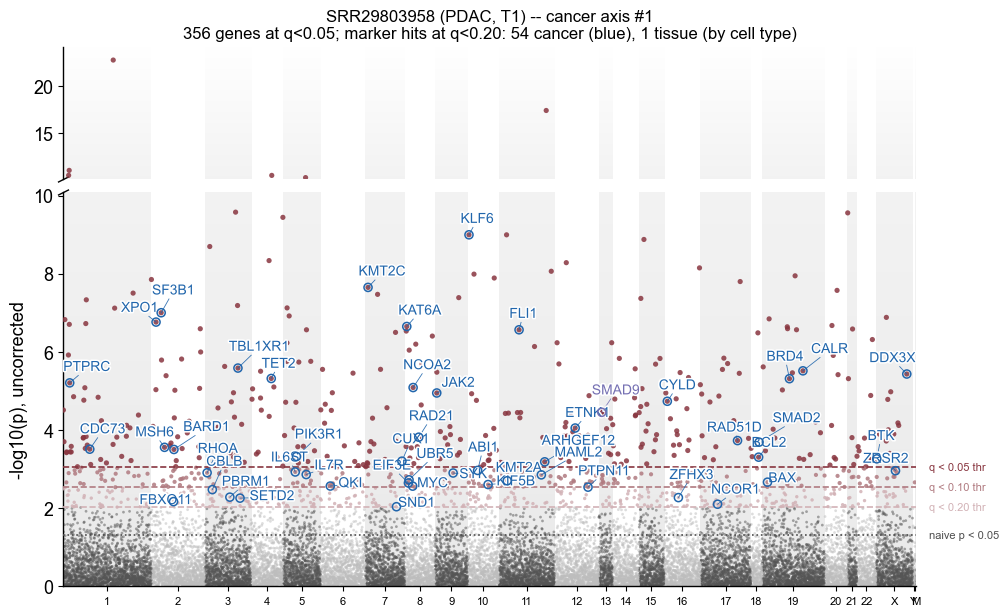

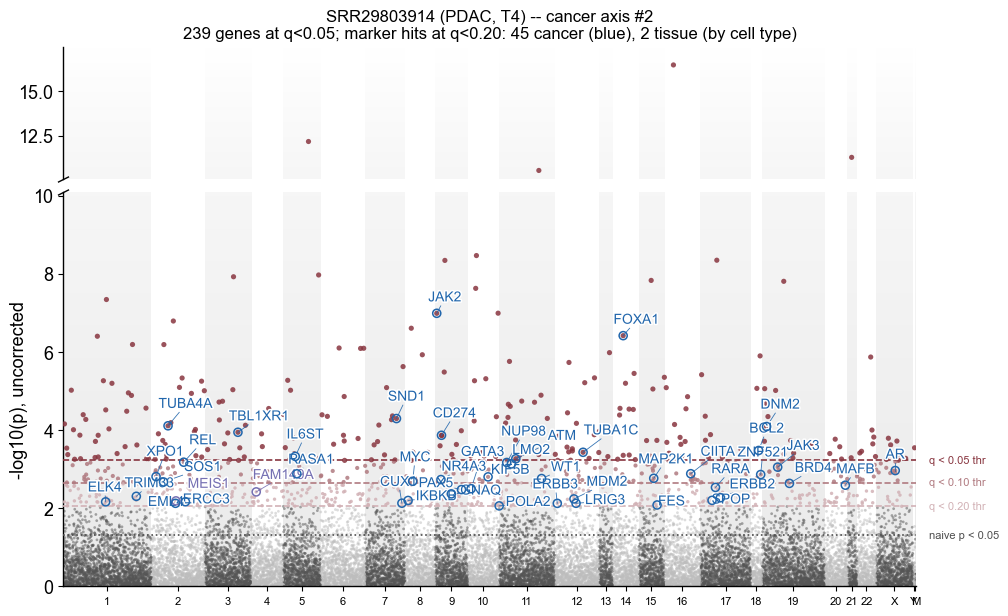

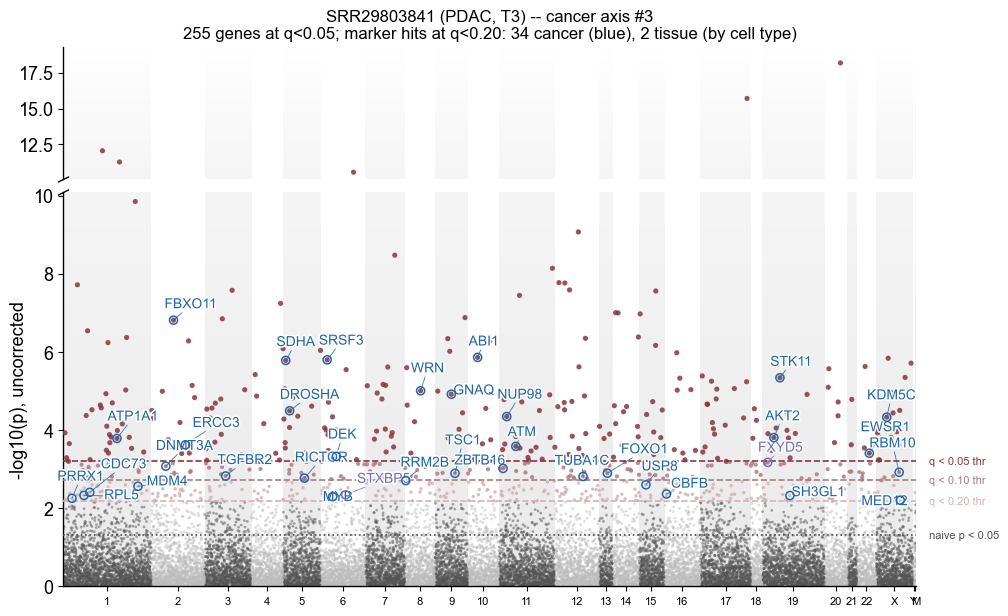

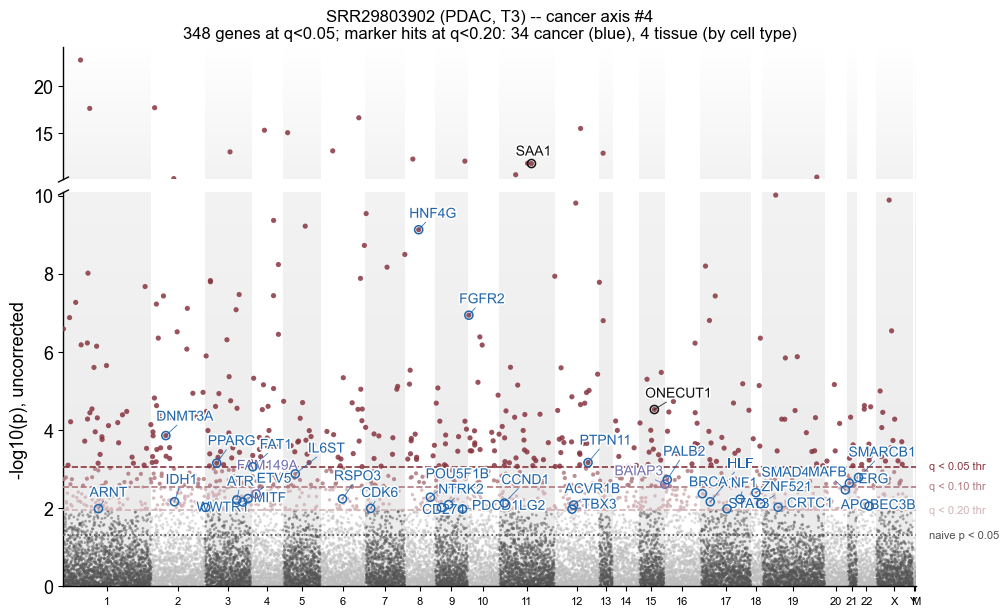

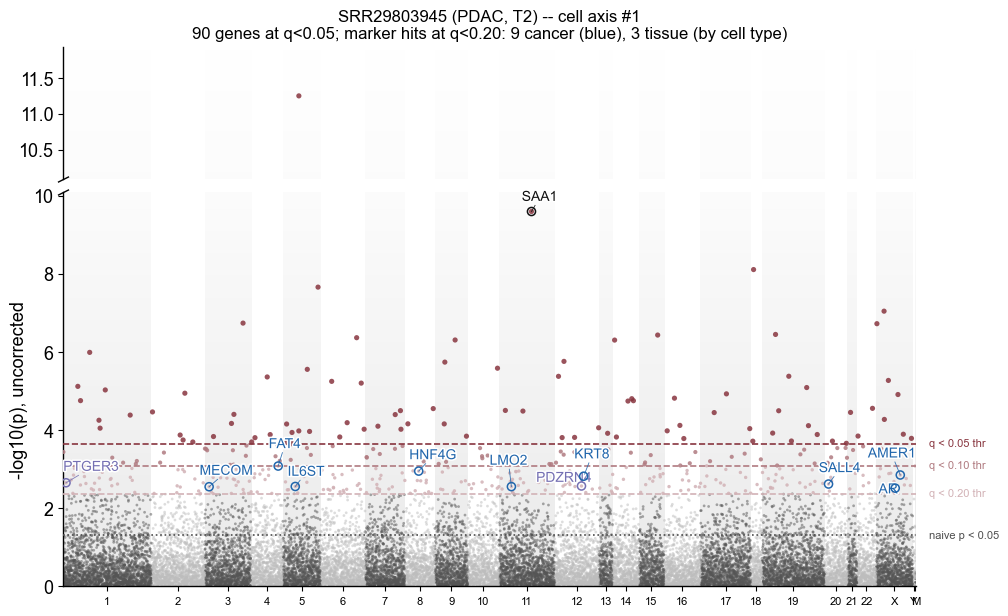

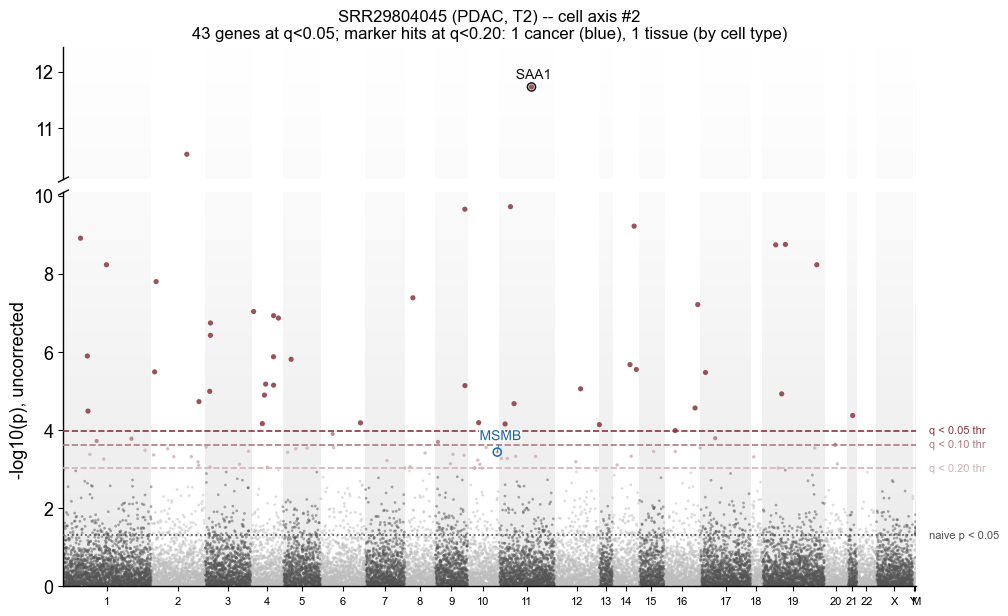

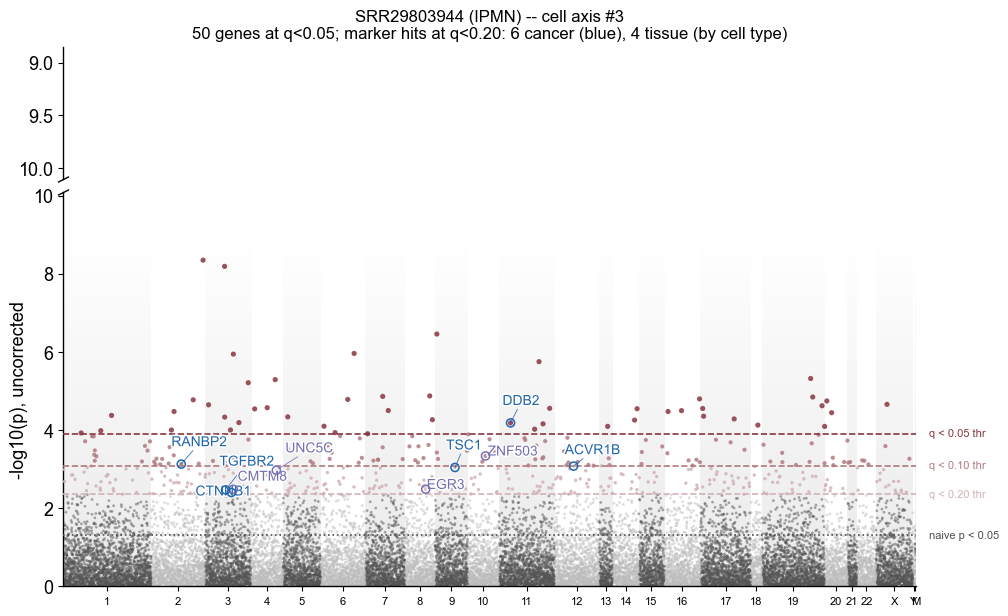

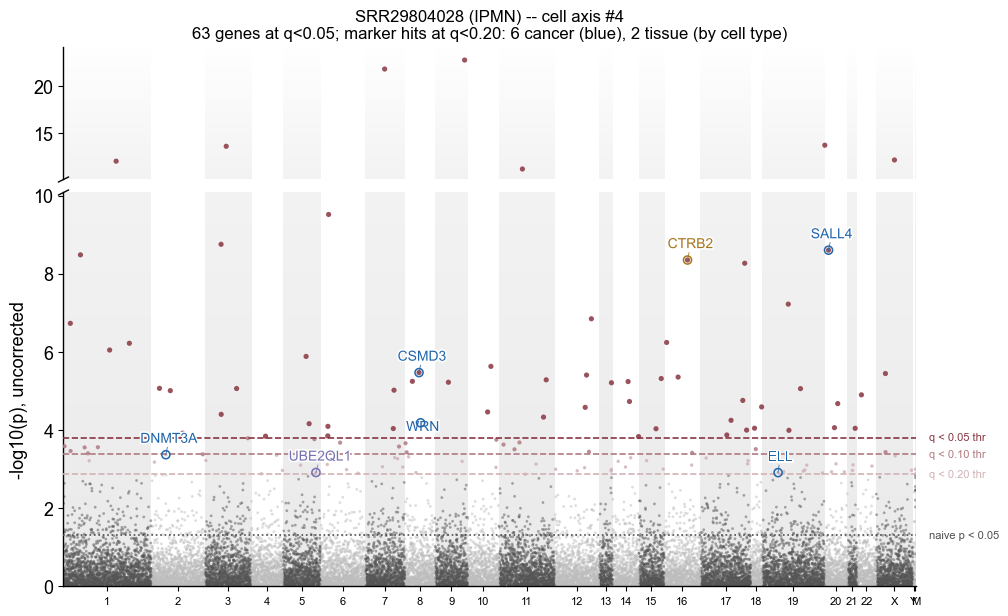

In [12]:
import matplotlib.colors as mcolors
import matplotlib.patheffects as pe
from adjustText import adjust_text

Q_TIERS = [0.05, 0.10, 0.20]
TIER_BASE = "#88353F"
CANCER_C = '#2166AC'
SET_C = {'acinar': '#A6761D', 'islet': '#7570B3', 'ductal': '#111111'}
BAND_C = '#F5F5F5'
NAIVE_P = 0.05
MAX_LABELS = 50
BRK_MULT, BRK_FLOOR = 3.0, 8.0  # break at this multiple of the q<0.05 cut, never below the floor
BRK_SLOPE, BRK_TICK = 0.5, 8  # slope and size of the diagonal break marks on the y axis
LABEL_DY = 0.015  # label offset above its point, as a fraction of that panel's y span
THR_LABEL_GAP = 0.03  # min spacing between threshold labels, as a fraction of the lower panel
LABEL_MAX_MOVE = (40, 40)  # px a label may drift from its point -- caps the leader-line length
LEADER_PAD = 1.5           # px between the label box and where its leader line starts
LEADER_MIN = 4             # px: shorter than this and the label already sits on its point

SHADES = [mcolors.to_hex(1 - w + w * np.array(mcolors.to_rgb(TIER_BASE))) for w in (1.0, 0.66, 0.38)]

GRAD_START_COLOR = '#EAEAEA'  # 바닥 색상 (필요시 '#F5F5F5' 또는 더 짙은 색으로 변경)
GRAD_END_COLOR = '#FFFFFF'    # 위쪽 색상 (하얀색)

grad_data = np.linspace(0, 1, 256).reshape(-1, 1)
band_cmap = mcolors.LinearSegmentedColormap.from_list('band_grad', [GRAD_START_COLOR, GRAD_END_COLOR])
name2row = {n: i for i, n in enumerate(names_dis)}
chrom_idx = chrom_of.reindex(gene_names).astype(str).map(chrom_rank).fillna(len(CHROM_ORDER)).astype(int).values
chrom_color = np.where(chrom_idx % 2 == 0, "#555555", '#bdbdbd')

seq = chrom_of.values
edges, start = [], 0
for k in range(len(seq)):
    if k + 1 == len(seq) or seq[k + 1] != seq[k]:
        edges.append((start - 0.5, k + 0.5))
        start = k + 1


def marker_color(j, kind):
    return CANCER_C if kind == 'cancer' else SET_C[set_of_col[j]]

def draw_points(a, keep, tier, y, y_max):
    for b, (x0, x1) in enumerate(edges):
        if b % 2 == 0:
            a.imshow(
                grad_data, 
                aspect='auto', 
                extent=[x0, x1, 0, y_max], 
                origin='lower', 
                cmap=band_cmap, 
                zorder=0
            )

    m = keep & (tier == 0)
    a.scatter(x_pos[m], y[m], c=chrom_color[m], s=4, alpha=0.5, edgecolors='none', zorder=2)
    for lvl, sh, sz in zip(range(len(Q_TIERS), 0, -1), SHADES, (14, 9, 6)):
        m = keep & (tier == lvl)
        a.scatter(x_pos[m], y[m], c=sh, s=sz, alpha=0.85, edgecolors='none', zorder=3)


def draw_labels(a, fig, subset, y, span):
    """Rings, haloed gene names and leader lines clipped at each label's bounding box."""
    for j, kind, _, _ in subset:
        a.scatter(x_pos[j], y[j], s=34, facecolors='none', edgecolors=marker_color(j, kind),
                  lw=1.1, zorder=8)
    texts = []
    for j, kind, _, _ in subset:
        t = a.text(x_pos[j], y[j] + LABEL_DY * span, sym_of.iloc[j], zorder=7,
                   color=marker_color(j, kind), ha='center', va='bottom')
        t.set_path_effects([pe.withStroke(linewidth=2.2, foreground='white')])
        texts.append(t)
    if not texts:
        return
    adjust_text(texts, ax=a, force_pull=(0.1, 0.1), max_move=LABEL_MAX_MOVE)
    fig.canvas.draw()
    inv = a.transData.inverted()
    for t, (j, kind, _, _) in zip(texts, subset):
        bb = t.get_window_extent()
        px, py = a.transData.transform((x_pos[j], y[j]))
        cx, cy = bb.x0 + bb.width / 2, bb.y0 + bb.height / 2
        dx, dy = px - cx, py - cy
        sx = (bb.width / 2 + LEADER_PAD) / abs(dx) if dx else np.inf
        sy = (bb.height / 2 + LEADER_PAD) / abs(dy) if dy else np.inf
        f = min(sx, sy, 1.0)
        if np.hypot(dx, dy) * (1 - f) < LEADER_MIN:
            continue
        x0, y0 = inv.transform((cx + dx * f, cy + dy * f))
        a.plot([x0, x_pos[j]], [y0, y[j]], color=marker_color(j, kind), lw=0.6, alpha=0.9, zorder=6)


for sample, axis, rank in CURATED:
    row = curate.loc[sample]
    z = Z_shash[name2row[sample]]
    p = 2 * norm.sf(np.abs(np.nan_to_num(z)))
    p[~np.isfinite(z)] = np.nan
    neglog10p = -np.log10(np.clip(p, 1e-300, 1))

    crit = {q: bh_crit_p(p, q) for q in Q_TIERS}
    tier = np.zeros(len(gene_names), dtype=int)  # 1 = q<0.20 only ... 3 = q<0.05
    for lvl, q in enumerate(sorted(Q_TIERS, reverse=True), start=1):
        if np.isfinite(crit[q]):
            tier[p <= crit[q]] = lvl

    ybrk = 10.1
    hi = neglog10p > ybrk

    sets = {'cancer': cancer_cols_of.get(row['phenotype'], []), 'tissue': cell_cols}
    scores = {'cancer': pheno_scores.get(row['phenotype'], {}), 'tissue': cell_detect_of}
    ranked = {k: sorted([(j, k, tier[j], scores[k].get(sym_of.iloc[j], 0.0)) for j in cols if tier[j] > 0],
                        key=lambda t: (-t[2], -t[3])) for k, cols in sets.items()}
    labels = ranked['tissue'][:MAX_LABELS]
    seen_sym = {sym_of.iloc[j] for j, *_ in labels}  
    for e in ranked['cancer']:
        if len(labels) == MAX_LABELS:
            break
        if sym_of.iloc[e[0]] not in seen_sym:
            seen_sym.add(sym_of.iloc[e[0]])
            labels.append(e)
    n_hit = {k: len(v) for k, v in ranked.items()}

    fig, (ax_hi, ax) = plt.subplots(2, 1, figsize=(11, 7), sharex=True,
                                    gridspec_kw=dict(height_ratios=[1.0, 3.0], hspace=0.05))
    ytop = max(neglog10p[np.isfinite(neglog10p)]) * 1.06
    ax.set_ylim(0, ybrk)
    ax_hi.set_ylim(ybrk, ytop)
    ytop = max(neglog10p[np.isfinite(neglog10p)]) * 1.06
    ax.set_ylim(0, ybrk)
    ax_hi.set_ylim(ybrk, ytop)
    for a, keep, span in ((ax, ~hi, ybrk), (ax_hi, hi, ytop - ybrk)):
        draw_points(a, keep & np.isfinite(neglog10p), tier, neglog10p, ytop)
        draw_labels(a, fig, [e for e in labels if hi[e[0]] == (a is ax_hi)], neglog10p, span)

    lines = [(-np.log10(NAIVE_P), '#4D4D4D', ':', f'naive p < {NAIVE_P}')]
    lines += [(-np.log10(crit[q]), sh, '--', f'q < {q:.2f} thr')
              for q, sh in zip(sorted(Q_TIERS), SHADES) if np.isfinite(crit[q])]
    for y, c, ls, _ in lines:
        ax.axhline(y, color=c, ls=ls, lw=1.2, zorder=4)
    gap, ly = THR_LABEL_GAP * ybrk, 0
    for y, c, _, lab in sorted(lines):
        ly = max(y, ly + gap) if ly else y
        ax.text(1.015, ly, lab, color=c, transform=ax.get_yaxis_transform(), ha='left',
                va='center', fontsize=FS_ANNOT_SM, clip_on=False, zorder=6)

    ax.spines['top'].set_visible(False)
    ax_hi.spines['bottom'].set_visible(False)
    ax_hi.tick_params(axis='x', length=0)
    dkw = dict(marker=[(-1, -BRK_SLOPE), (1, BRK_SLOPE)], markersize=BRK_TICK, linestyle='none',
               color='k', mec='k', mew=1.0, clip_on=False)
    ax_hi.plot([0], [0], transform=ax_hi.transAxes, **dkw)
    ax.plot([0], [1], transform=ax.transAxes, **dkw)
    ax.set_xticks(tick_x)
    ax.set_xticklabels(tick_lab, fontsize=FS_ANNOT_SM)
    ax.set_xlim(0, len(gene_names))
    ax.set_ylabel('-log10(p), uncorrected')
    tstage = '' if not np.isfinite(row['tumor_stage']) else f", T{int(row['tumor_stage'])}"
    ax_hi.set_title(f"{sample} ({row['stage']}{tstage}) -- {axis} axis #{rank}\n"
                    f"{int(row['n_sig_genome'])} genes at q<{FDR_Q}; marker hits at q<{CURATE_Q:.2f}: "
                    f"{n_hit['cancer']} cancer (blue), {n_hit['tissue']} tissue (by cell type)",
                    fontsize=FS_ANNOT_LG)
    fig.savefig(FIGDIR / f'manhattan_{axis}{rank}_{sample}.png', bbox_inches='tight')
    print(f"{sample} {axis}{rank}: BH cut p " +
          " ".join(f"q{q:g}={crit[q]:.2e}" if np.isfinite(crit[q]) else f"q{q:g}=none" for q in Q_TIERS) +
          f" vs naive {NAIVE_P} | genes per tier 3/2/1 = "
          f"{int((tier==3).sum())}/{int((tier==2).sum())}/{int((tier==1).sum())}"
          f" | break {ybrk:.1f}, {int(hi.sum())} above")


In [13]:
QS = [0.05, 0.10, 0.15, 0.20, 0.25]
SWEEP_SUMMARY_PATH = ZDIR / 'fdr_threshold_sweep_summary.csv'

if SWEEP_SUMMARY_PATH.exists():
    sweep_summary = pd.read_csv(SWEEP_SUMMARY_PATH)
else:
    p_all = 2 * norm.sf(np.abs(Z_shash))
    summary_rows = []
    for q in QS:
        tag = '' if q == FDR_Q else f'_q{q:g}'.replace('.', '')
        path = ZDIR / f'sample_bh_sig{tag}.csv'
        if path.exists():
            df_q = pd.read_csv(path)
        else:
            n_sig_q = np.zeros(len(names_dis), dtype=int)
            for i in range(len(names_dis)):
                row = p_all[i]
                row = row[np.isfinite(row)]
                if len(row) == 0:
                    continue
                n_sig_q[i] = int(bh_fdr_reject(row, q=q).sum())
            df_q = pd.DataFrame({'sample': names_dis, 'phenotype': phenotype_dis,
                                 'ood_keep': ood_keep, 'n_sig': n_sig_q})
            df_q.to_csv(path, index=False)
        g = (df_q[df_q.ood_keep].groupby('phenotype')['n_sig']
             .agg(median='median', mean='mean', max='max').reset_index())
        g['q'] = q
        summary_rows.append(g)
    sweep_summary = pd.concat(summary_rows, ignore_index=True)
    sweep_summary.to_csv(SWEEP_SUMMARY_PATH, index=False)

sweep_summary

,phenotype,median,mean,max,q
0,CAD_HF+,8.0,9.884615,33,0.05
1,CAD_HF-,5.5,70.000000,962,0.05
2,Colorectal Cancer,14.0,113.600000,1002,0.05
3,Esophagus Cancer,15.0,76.680000,372,0.05
4,HIV,57.5,196.000000,1478,0.05
...,...,...,...,...,...
100,Pancreatic Cancer,518.0,518.000000,666,0.25
101,Pancreatitis,26.0,78.632911,751,0.25
102,Pre-eclampsia,14.0,169.688525,1396,0.25
103,Stomach Cancer,115.0,713.090909,5979,0.25
